# 추가 성능 개선: 성공한 부분과 실패한 부분

**v12의 IF 전체와 K-means Adapter/앙상블은 Accuracy·Precision·Recall·F1이 모두 상승했다.**
새 버전이라는 이유로 전체 묶음을 배포하지 않는다. 원본 CSV/정답/기존 운영 v1은 그대로다.

추천 handoff는 **v12 관측 이력별 분기 IF/K-means 연구 후보**다.
v11은 정상 대조 사례를 보정용으로 재사용한 실험이다. IF의 F1/Recall은 더 높지만 calibration/test 원본 템플릿 공유가 있으므로
더 엄격한 v10/v12와 구분해서 읽는다. 실제 운영에서의 독립 성능이라고 주장하지 않는다.

> 이번 공유 범위: 최종 v12 IF/K-means, 전체 연구 코드·노트북, 원본 inputs.json·학습/검증 캐시. 기간별 원본과 벤치마크 CSV·정답·행별 NPZ는 보류했습니다. 이전 실험의 모델 바이너리는 제외했으며 저장된 결과와 실제 재실행 가능 범위는 다릅니다. 최신 결과는 model_research_v8/results.ipynb와 benchmark_difficulty/comparison.ipynb, 로드 안내는 패키지 README.md·INTEGRATION.md를 참고하세요.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'code/model_research_v8/report.py').exists())
sys.path.insert(0,str(ROOT/'code'))
from model_research_v8 import report
from model_research_v8.models import METHODS
report.setup()
pd.set_option('display.max_columns',15)
s=report.read();audit=report.read(name='audit')

## 1. Accuracy·Precision·Recall·F1을 모두 개선했나?

IF 전체 비교부터 본다. 3개 버전은 동일한 2,167,766개 1분 의사결정을 사용했다.
F1 상승이 Precision 하락으로 만들어진 것인지, 오탐 감소가 Recall 희생으로 만들어진 것인지 구분한다.

In [2]:
rows=[]
for v in ('v7','v10','v11','v12'):
    r=report.read(v)['pooled'][0]
    rows.append({'버전':v,**{label:r[k]*100 for label,k in (('Accuracy (%)','accuracy'),('Precision (%)','precision'),('Recall (%)','recall'),('F1 (%)','f1'),('정상 오탐 (%)','normal_false_positive_rate'))}})
display(pd.DataFrame(rows).round(2))
display(Markdown('v10: 원래 분리된 정상 참고 집단 유지. v11: 이전 합성 정상 대조 사례로 보정 집단 변경. 같은 프로토콜의 반복 실험이 아님.'))

,버전,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,v7,84.89,69.81,15.93,25.95,1.37
1,v10,85.28,76.35,16.47,27.09,1.02
2,v11,85.25,73.39,17.58,28.36,1.27
3,v12,85.35,74.30,18.00,28.98,1.24


v10: 원래 분리된 정상 참고 집단 유지. v11: 이전 합성 정상 대조 사례로 보정 집단 변경. 같은 프로토콜의 반복 실험이 아님.

### 핵심 수치와 판단

- IF v10 전체: F1 **25.95%→27.09%**, Precision **69.81%→76.35%**, Recall **15.93%→16.47%**, 정상 오탐 **1.37%→1.02%**.
- IF v11 전체: F1 **28.36%**, Precision **73.39%**, Recall **17.58%**, 정상 오탐 **1.27%**.
- IF v12 전체: F1 **28.98%**, Precision **74.30%**, Recall **18.00%**, 정상 오탐 **1.24%**.
- K-means v12 앙상블: F1 **35.92%→37.86%**, Precision **51.58%→57.59%**, Recall **27.55%→28.20%**, 정상 오탐 **5.15%→4.14%**.
- 모든 경로가 네 지표 전부 좋아진 것은 아니다. IF 앙상블/K-means 전체에는 Precision 또는 오탐 tradeoff가 있다.
- v11의 템플릿 공유와 합성 도메인 보정 효과를 실제 미래 로그 일반화 효과와 혼동하지 않는다.

## 2. 모든 경로를 비교하면?

IF 기준은 최근 v7, K-means 기준은 이전에 보존하기로 했던 강한 v4다.
실패한 v7 K-means만 기준으로 삼아 개선 폭을 부풀리지 않는다.

,모델,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,85.35,74.30,18.00,28.98,1.24
1,IF Adapter,84.73,73.29,12.72,21.68,0.92
2,IF 앙상블,85.11,69.13,18.74,29.49,1.67
3,K-means 전체,85.09,62.59,25.41,36.15,3.02
4,K-means Adapter,84.06,54.66,23.47,32.84,3.88
5,K-means 앙상블,84.63,57.59,28.20,37.86,4.14


,모델,기준 버전,기존 Accuracy (%),새 Accuracy (%),기존 Precision (%),새 Precision (%)
0,IF 전체,v7,84.89,85.35,69.81,74.30
1,IF Adapter,v7,84.36,84.73,64.84,73.29
2,IF 앙상블,v7,84.84,85.11,71.53,69.13
3,K-means 전체,v4,85.13,85.09,63.55,62.59
4,K-means Adapter,v4,83.65,84.06,51.75,54.66
5,K-means 앙상블,v4,83.67,84.63,51.58,57.59


,모델,기존 Recall (%),새 Recall (%),기존 F1 (%),새 F1 (%),기존 정상 오탐 (%),새 정상 오탐 (%)
0,IF 전체,15.93,18.00,25.95,28.98,1.37,1.24
1,IF Adapter,12.76,12.72,21.33,21.68,1.38,0.92
2,IF 앙상블,14.52,18.74,24.14,29.49,1.15,1.67
3,K-means 전체,24.51,25.41,35.38,36.15,2.80,3.02
4,K-means Adapter,23.01,23.47,31.86,32.84,4.27,3.88
5,K-means 앙상블,27.55,28.20,35.92,37.86,5.15,4.14


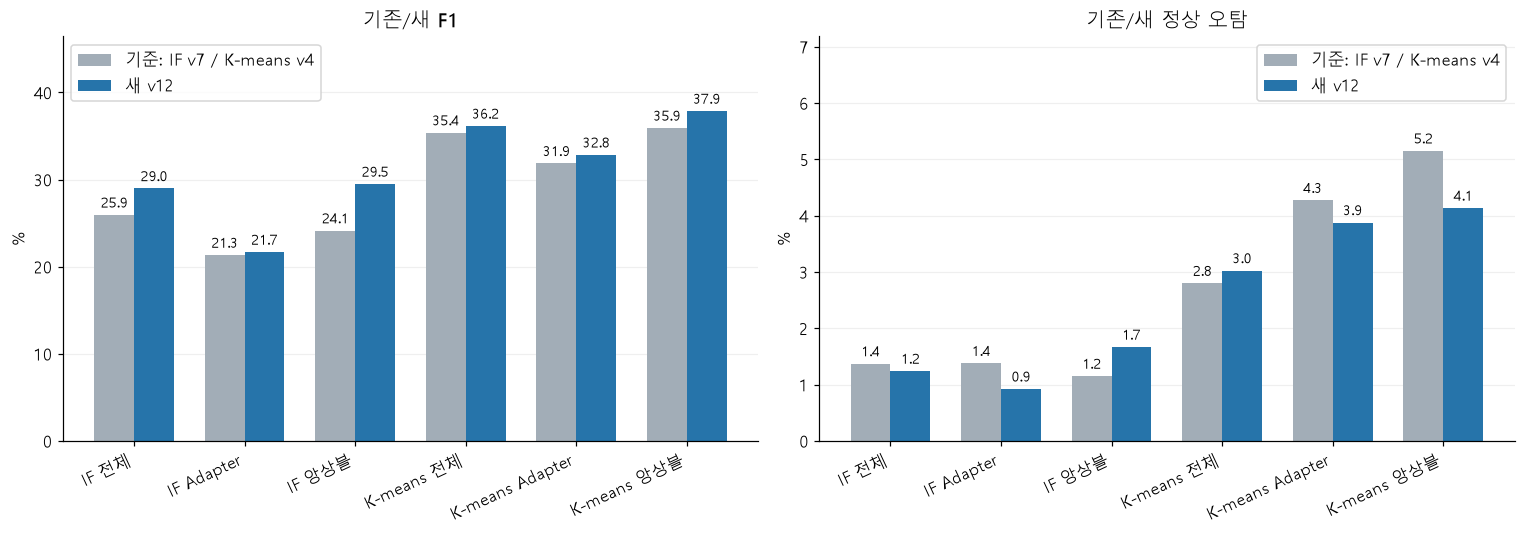

In [3]:
display(report.metrics(s['pooled']))
c=report.comparison()
display(c[['모델','기준 버전','기존 Accuracy (%)','새 Accuracy (%)','기존 Precision (%)','새 Precision (%)']])
display(c[['모델','기존 Recall (%)','새 Recall (%)','기존 F1 (%)','새 F1 (%)','기존 정상 오탐 (%)','새 정상 오탐 (%)']])
report.bars();plt.show()

## 3. 엄밀하게 확인한 문제와 접근

| 문제 | 확인 근거 | 시도 |
|---|---|---|
| 단건 지연이 요약값에 묻힘/초기 관측 부족 | 기존 IF 개별 지연 F1 0%, v8 IF 전체 88.51% | 개별 완료 Process에서 조건부 꼬리 위치 계산, 1분 최대값 보존 |
| 업무·처리량에 따라 정상 시간이 다름 | 같은 절대 소요시간의 의미가 다름 | Adapter+ProcessID+정확한 처리건수 우선, 부족하면 계층 fallback |
| 희소 실행을 입력 중단으로 오해 | 짧은 정상 사례에 무실행 창이 많음 | 직전 비어 있지 않은 실행 분 3개 이상인 경우에만 안정 패턴 분기 평가 |
| 지연 분기가 기존 중단 탐지를 억제 | v8/v9는 지연 F1이 높아져도 중단 F1 감소 | 기존 IF v7/K-means v4를 동결한 분기와 새 지연 분기 결합 |
| 점수 크기와 정상 보정 분포 불일치 | 새 확인 사례의 FPR이 탐색 결과보다 높음 | 채널별 정규화, 군집 공분산 후보, 정상 두 집단의 보수적 threshold, 대표 정상 보정 |
| 평균 성능이 어려운 시나리오를 가림 | 개별·집단·점진적 악화 및 Hard 성능 차이 | 합산/시나리오/관측 상태/사건 지표를 분리 |

문제 원인에 대한 해석에는 추론이 포함된다. 모든 변경 하나의 인과적 효과가 확인된 것은 아니다.
아래 분기 제거 실험과 원래 결과를 같이 읽는다.

## 4. 조건부 소요시간 피처의 의미

정상 train에서 `(Adapter, ProcessID, totalCount)`의 소요시간 분포를 저장한다. 최소 원본 20행.
부족하면 `(Adapter,totalCount)` → `(Adapter,ProcessID)` → `Adapter` → 전체 순서로 fallback한다.
IDs는 참고 집단 선택용이며 트리·거리의 숫자 피처가 아니다.

소요시간 d, 정상 n개 중 d 미만의 개수 L에 대해 위쪽 꼬리 `(n-L+1)/(n+1)`의 `-log`를 피처로 만든다.
아래쪽 꼬리도 만들어 지나치게 빠른/관계가 어긋난 값의 후보 신호를 남긴다. 동률은 보수적으로 처리한다.
**이 피처 자체가 확정 이상 하드 룰이나 보장된 p-value는 아니다.**

현재 분 완료 로그만 쓰는 최대값, 5분 평균, 과거 대비 변화·EWMA·초기 관측 대비 변화 후보를 시험했다.
최종 v10 IF 지연 분기는 최대/평균 꼬리 4개, K-means 분기는 최대 꼬리 2개를 선택했다.
현재 분이 끝나는 시각 t에 완료시각 `<t`인 로그만 사용한다. 진행 중인 Process의 미래 종료시간을 쓰지 않는다.

## 5. 논문 근거와 구현 범위

- [COPOD, ICDM 2020](https://arxiv.org/abs/2009.09463): 경험적 분포의 꼬리를 이상 점수에 활용하는 아이디어 참고.
  이번 조건부 CDF는 **COPOD/ECOD 재현이 아니라 자체 피처 변환**이다.
- [NCAD, 2021](https://arxiv.org/abs/2107.07702): 과거 맥락과 현재 구간 비교의 참고. 이번에 NCAD 신경망을 훈련하지 않았다.
- [Kim 등, ICLR 2022](https://arxiv.org/abs/2109.05257): point adjustment 과대평가를 피하고 분 단위 지표와 사건 지표 분리.
- IF와 K-means의 정상 학습 방식은 유지. label은 새 검증에서 하이퍼파라미터 선택에만 사용했다.
- 군집별 diagonal/full 공분산 거리도 시험했지만 성능 개선 후보로 채택되지 않았다. Full covariance는 고정 50% diagonal shrinkage 후보이며 최적 공분산 추정 재현이 아니다.

## 6. 실험별로 무엇이 성공/실패했나?

v8: 조건부 지연 피처·트래픽/지연 채널. 단건 지연은 크게 좋아졌지만 공통 threshold가 중단 탐지를 억제.
v9: 지연 피처 단순화·정상 두 집단의 높은 threshold. 일부 지연 개선, 전체 Recall 손실.
v10: 기존 안정 패턴 분기 동결 + 조건부 지연 분기. IF 전체의 네 지표 모두 개선, K-means 종합 실패.
v11: v10의 트리/군집을 그대로 두고 정상 보정 자료 변경. IF 전체 F1/Recall 추가 상승, K-means는 여전히 실패.
v12: 3개 이전 실행 분이 관측되기 전에는 지연에 강한 v8, 이후에는 IF v10/K-means v4를 사용.
관측 이력 기반 분기라 시나리오/정답/총 사례 길이를 보지 않는다. 새 파라미터 탐색 없이 새 확인 사례 전에 동결.
원래 분리 정상 참고 집단을 유지하며 v11의 정상 proxy 보정은 사용하지 않는다.

이전 정상 대조 사례는 v11부터 학습용 보정 자료다. 더 이상 '미사용 검증 집단'이라고 부르지 않는다.

In [4]:
display(report.progress())
prep=report.read('v11',name='preparation')
display(pd.DataFrame([{'집단':'정상 calibration','창 수':prep['normal_calibration_windows'],'사례 수':prep['normal_calibration_cases']},
                      {'집단':'정상 threshold','창 수':prep['normal_threshold_windows'],'사례 수':prep['normal_threshold_cases']}]))

,버전,모델,F1 (%),Recall (%),정상 오탐 (%)
0,v4,IF 전체,23.28,16.94,5.70
1,v4,IF Adapter,22.43,15.50,4.52
2,v4,IF 앙상블,23.55,16.17,4.22
3,v4,K-means 전체,35.38,24.51,2.80
4,v4,K-means Adapter,31.86,23.01,4.27
5,v4,K-means 앙상블,35.92,27.55,5.15
6,v7,IF 전체,25.95,15.93,1.37
7,v7,IF Adapter,21.33,12.76,1.38
8,v7,IF 앙상블,24.14,14.52,1.15
9,v7,K-means 전체,21.89,12.97,1.10


,집단,창 수,사례 수
0,정상 calibration,71573,2160
1,정상 threshold,71636,2160


## 7. 새 확인 사례에서는 어땠나?

v8~v11은 기본 6시나리오 360개씩 주입 사례+정상 쌍을 1,080개 탐색/1,080개 확인으로 나눴다.
v12는 동결 후 새 240개×6종, 주입 1,440개+정상 1,440개 전부 확인용으로 평가했다. 재선택하지 않았다.
확인 지표를 보고 재선택하지 않았다. Hard는 탐색에 쓰지 않았다.
v11 기준은 합산 F1 평균, 경로별 정상 오탐 ≤2%, 시나리오/경로별 ≤5%.
확인 집단에서 오탐이 목표를 넘은 사실도 공개한다. '선택 제약 충족'이 운영 오탐 보장은 아니다.

In [5]:
display(report.confirmation())
selection=report.read(name='selection')
display({k:selection[k] for k in ('routing','new_hyperparameter_search','frozen_before_new_validation','normal_source_reference_template_holdout_preserved')})
display(pd.DataFrame(s['thresholds']))

,설정,모델,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,baseline_v4,IF 전체,82.33,39.33,18.22,24.90,5.38
1,baseline_v4,IF Adapter,82.58,41.04,19.17,26.13,5.27
2,baseline_v4,IF 앙상블,83.00,43.55,19.36,26.80,4.80
3,baseline_v4,K-means 전체,85.47,60.27,28.17,38.40,3.56
4,baseline_v4,K-means Adapter,82.43,42.45,26.17,32.38,6.80
5,baseline_v4,K-means 앙상블,82.97,45.77,32.24,37.83,7.32
6,baseline_v7,IF 전체,85.50,69.27,17.64,28.12,1.50
7,baseline_v7,IF Adapter,84.99,65.69,13.86,22.89,1.39
8,baseline_v7,IF 앙상블,85.46,71.30,16.00,26.13,1.23
9,baseline_v7,K-means 전체,85.18,65.65,16.32,26.14,1.64


{'routing': '3 prior nonempty arrival minutes; uses observed past, not scenario/severity/episode length.',
 'new_hyperparameter_search': False,
 'frozen_before_new_validation': True,
 'normal_source_reference_template_holdout_preserved': True}

,algorithm,settings,route,phase,quantile,global_weight,phase_aware,...,latency_quantile,joint_quantile,latency_raw_threshold,joint_thresholds,normalizer_median,cluster_radii,effective_k
0,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",GLOBAL,startup,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",GLOBAL,steady,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",DB.READER,startup,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",DB.READER,steady,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",DB.WRITER,startup,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",DB.WRITER,steady,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",FILE.READER,startup,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",FILE.READER,steady,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",FILE.WRITER,startup,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,if,"{'algorithm': 'if', 'samples': 256, 'rotations...",FILE.WRITER,steady,0.995,0.25,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 8. 시나리오와 모델별 역할

IF는 쉽게 분리되는 희귀 조합, K-means는 정상 중심에서 벗어난 거리를 본다.
조건부 지연 분기는 개인 업무의 정상 소요시간 관계를 피처로 만든다.
기존 분기는 원래 시간·트래픽·지연 피처를 같이 사용하므로 **순수 트래픽 모델이라고 부르지 않는다.**
모델 특징은 피처·정상 참고 자료·threshold까지 포함한 현재 설정의 결과다. 알고리즘의 보편적 우열이 아니다.

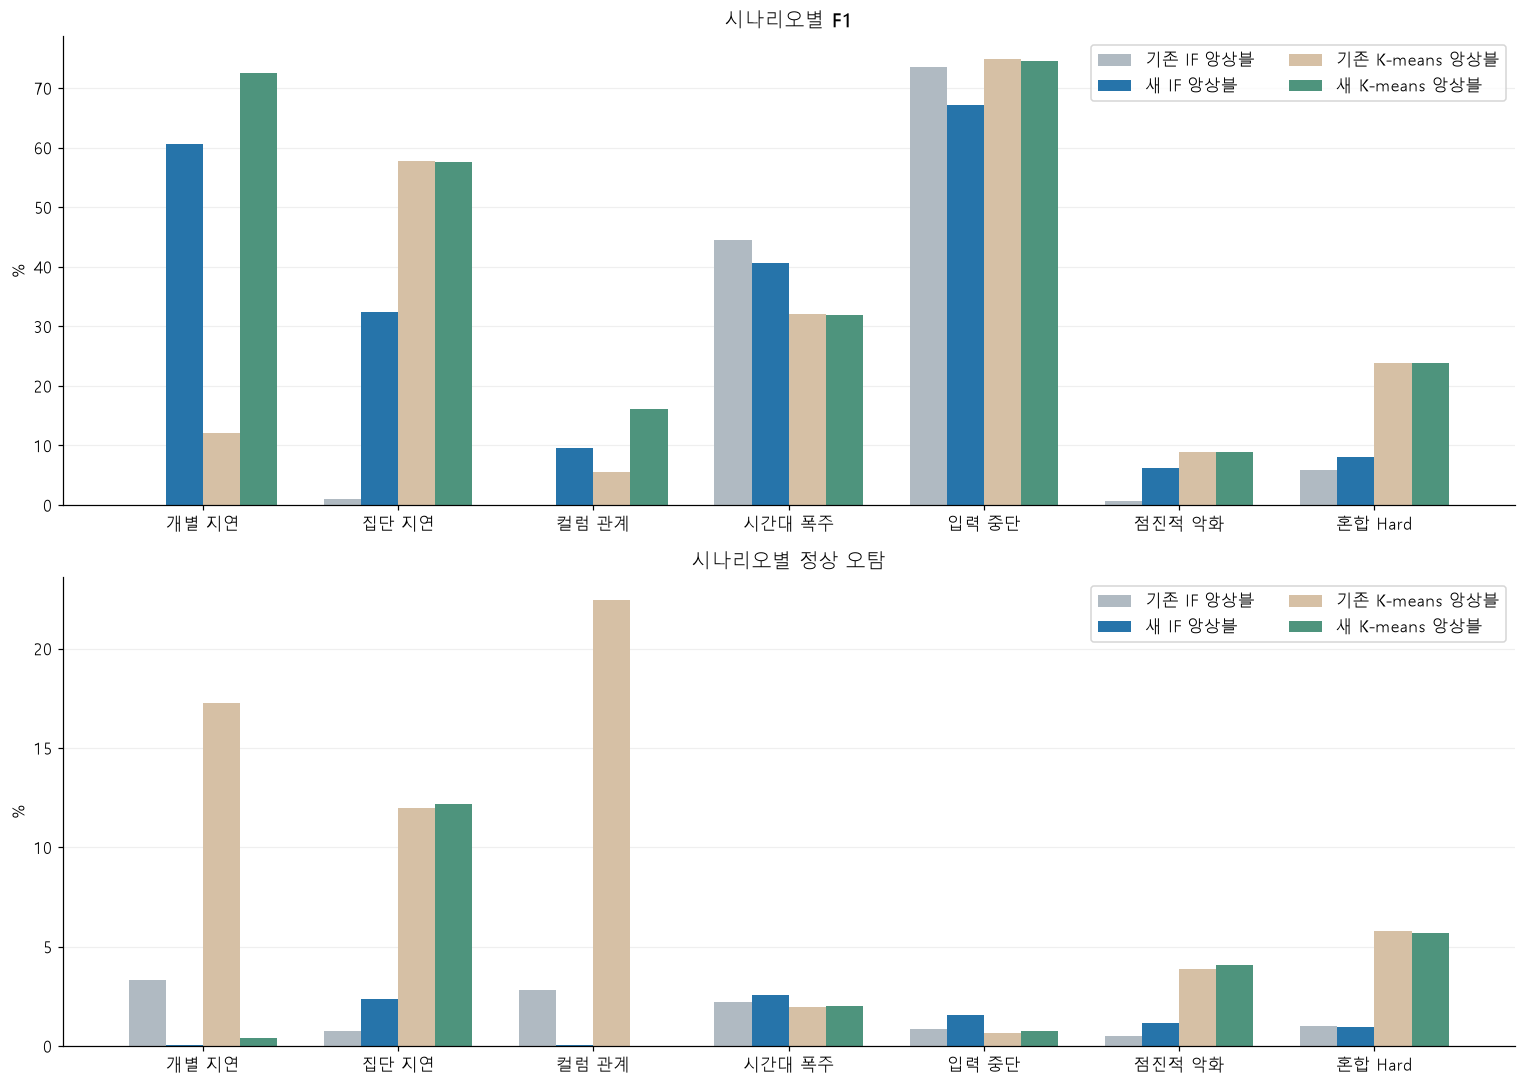

,시나리오,모델,F1 (%),Recall (%),정상 오탐 (%)
0,개별 지연,IF 전체,88.51,83.99,0.53
1,개별 지연,IF 앙상블,60.56,43.70,0.06
2,개별 지연,K-means 전체,72.76,59.74,0.41
3,개별 지연,K-means 앙상블,72.58,59.52,0.41
4,집단 지연,IF 전체,17.43,10.69,2.13
5,집단 지연,IF 앙상블,32.40,21.90,2.37
6,집단 지연,K-means 전체,58.94,65.82,10.25
7,집단 지연,K-means 앙상블,57.49,67.91,12.18
8,컬럼 관계,IF 전체,22.37,12.79,0.31
9,컬럼 관계,IF 앙상블,9.64,5.08,0.06


,모델,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,88.18,67.34,34.12,41.21,1.08
1,IF Adapter,87.07,66.94,20.65,28.87,0.70
2,IF 앙상블,87.45,74.15,26.96,36.10,1.30
3,K-means 전체,87.73,69.54,36.18,42.36,2.46
4,K-means Adapter,86.64,70.16,29.05,36.42,3.06
5,K-means 앙상블,87.38,70.11,37.75,43.60,3.24


In [6]:
report.scenarios();plt.show()
rows=[]
for d in s['datasets']:
    for i in (0,2,3,5):
        r=d['metrics'][i]
        rows.append({'시나리오':report.SCENARIOS[d['dataset']],'모델':report.LABELS[i], 'F1 (%)':r['f1']*100,'Recall (%)':r['recall']*100,'정상 오탐 (%)':r['normal_false_positive_rate']*100})
display(pd.DataFrame(rows).round(2))
display(report.metrics(s['basic_macro']))

## 9. 분기를 제거해서 확인한 효과

아래는 이전 v11 후보의 새 확인 사례에서 동일 하이퍼파라미터를 고정한 제거 실험이다. v12 제거 실험은 아니다.
제거한 경우 정상 참고 데이터에서 같은 분위수로 threshold를 다시 보정했지만, 확인 라벨로 다시 튜닝하지 않았다.
`baseline_only` 기존 분기만, `conditional_only` 조건부 지연만, `no_cadence_gate` 관측 주기 조건 제거,
`no_joint_calibration` 결합 보정 없이 각 분기의 양의 증거를 합친 경우다.

K-means는 새 분기 결합이 기존 분기를 희생했다. 결합 보정을 제거하면 Recall/F1은 올라가지만 오탐이 커졌다.
따라서 무조건 OR하면 성능이 개선된다는 결론은 틀리다.

In [7]:
display(report.ablations())

,알고리즘,제거/설정,경로,F1 (%),Recall (%),정상 오탐 (%)
0,if,complete,전체,31.75,21.56,2.73
1,if,complete,Adapter,25.66,15.81,1.42
2,if,complete,앙상블,31.34,20.83,2.32
3,if,baseline_only,전체,28.71,17.80,1.19
4,if,baseline_only,Adapter,23.60,14.14,1.09
5,if,baseline_only,앙상블,26.73,16.16,0.91
6,if,conditional_only,전체,6.84,3.83,1.55
7,if,conditional_only,Adapter,3.22,1.67,0.34
8,if,conditional_only,앙상블,9.04,5.11,1.53
9,if,no_cadence_gate,전체,31.42,21.56,3.01


## 10. 정상·이상 분포와 판정선

일반 막대 히스토그램이다. X축 `score-threshold`가 0보다 크면 이상 판정.
정상이 오른쪽이면 오탐, 주입 이상이 왼쪽이면 미탐이다.
파일당 최대 12,000개 표본, 양끝 0.5%는 끝 bin에 합침. 성능표는 전체 행.
정규분포가 목표가 아니라 정상/이상 겹침과 운영 경보 예산이 중요하다.

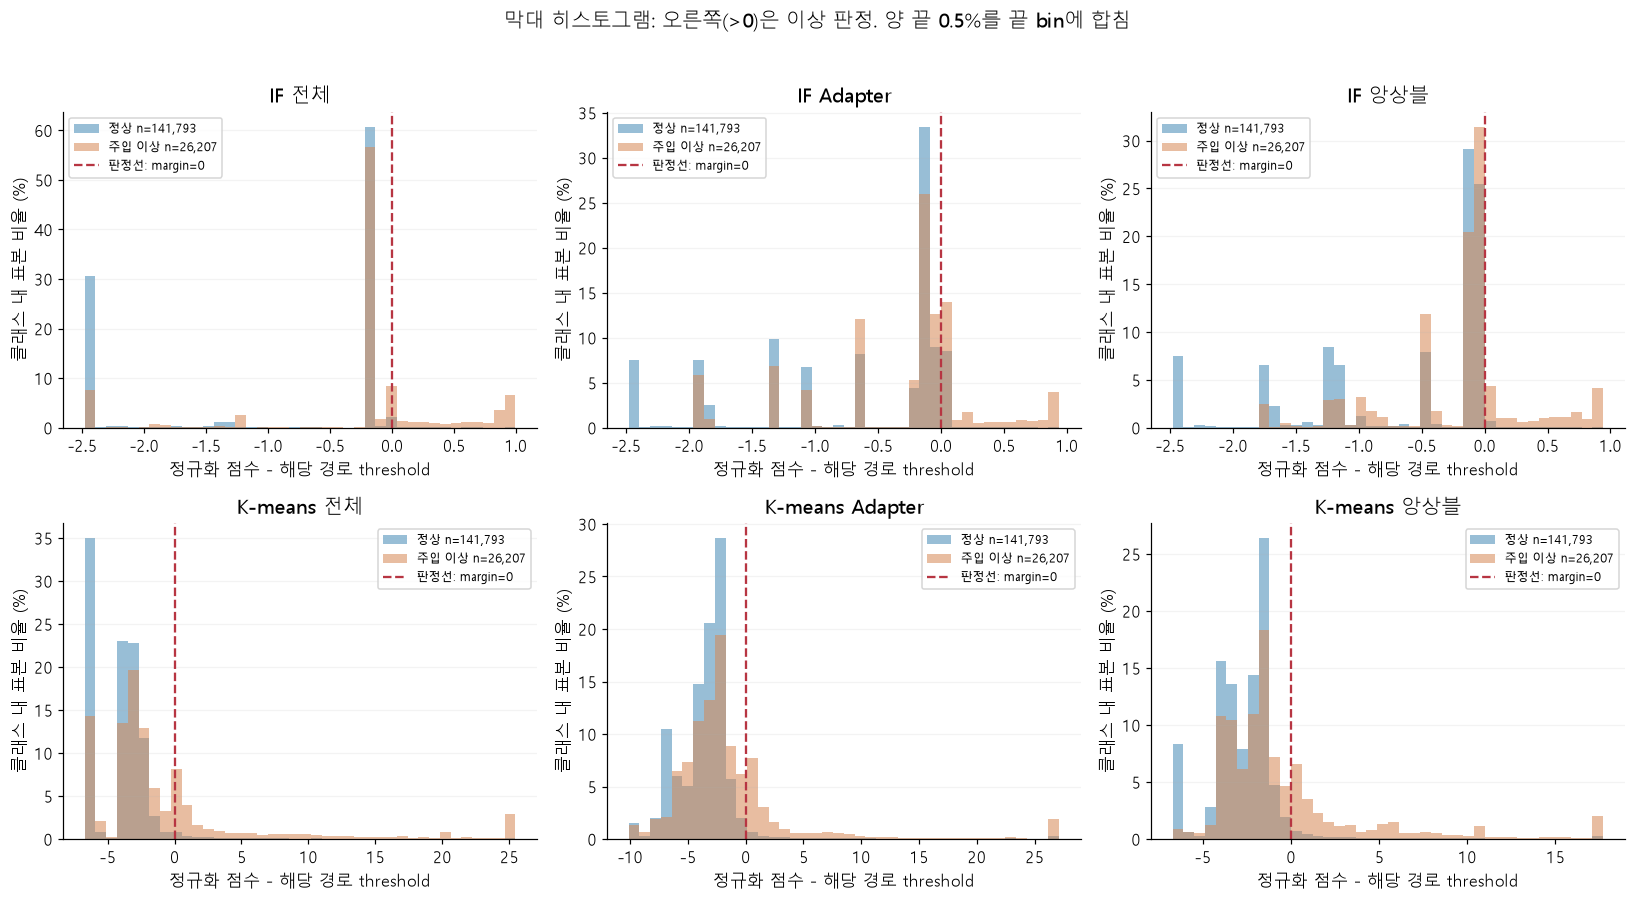

행별 예측 NPZ는 보류했습니다. 원래 실행에서 저장된 점수 분포 그림입니다.

In [8]:
if (ROOT/'reports/model_research_v12/individual_delay/observed.npz').is_file():
    report.distributions();plt.show()
else:
    from IPython.display import Image
    display(Image(filename=str(ROOT/'reports/model_research_v12/figures/figure_03.png')))
    display(Markdown('행별 예측 NPZ는 보류했습니다. 원래 실행에서 저장된 점수 분포 그림입니다.'))

## 11. Adapter·콜드스타트·관측 가능성

지원 전문가: DB.READER, DB.WRITER, FILE.READER, FILE.WRITER, SERVICE.EXECUTOR.
지원되지 않는 Adapter는 전체 점수·threshold와 정확히 동일하게 fallback한다.
완료 로그도 실행 주기도 없는 창에서는 두 분기 모두 충분한 근거가 없다. 이 행을 정상이라고 확정하거나 평가에서 빼지 않는다.
관측 부족에 따른 미탐도 Recall 분모에 그대로 남긴다.

In [9]:
display(pd.DataFrame(s['support']))
display(report.metrics(s['supported_only']))
rows=[]
for key,records in audit['group_metrics'].items():
    for i in (0,3):
        r=records[i]
        if r['f1'] is not None:rows.append({'집단':key,'모델':report.LABELS[i],'행 수':r['n'],'F1 (%)':r['f1']*100,'정상 오탐 (%)':r['normal_false_positive_rate']*100})
display(pd.DataFrame(rows).round(2))

,adapter,train,calibration,threshold,source_workflows,expert_available,reason
0,DATA.DECRYPTOR,0,607,0,{'calibration': 1},False,train<500; threshold<100; train_source_workflo...
1,DATA.ENCRYPTOR,0,626,0,{'calibration': 1},False,train<500; threshold<100; train_source_workflo...
2,DATA.MAPPER,628,656,650,"{'train': 2, 'calibration': 4, 'threshold': 6}",False,train_source_workflows<20; calibration_source_...
3,DATA.TRANSFORMER,657,654,646,"{'train': 5, 'calibration': 8, 'threshold': 19}",False,train_source_workflows<20; calibration_source_...
4,DB.DELETER,627,0,625,"{'train': 1, 'threshold': 1}",False,calibration<100; train_source_workflows<20; ca...
5,DB.EXECUTOR,631,654,644,"{'train': 1, 'calibration': 764, 'threshold': ...",False,train_source_workflows<20
6,DB.READER,656,649,652,"{'train': 1536, 'calibration': 469, 'threshold...",True,supported
7,DB.UPDATER,654,655,651,"{'train': 7, 'calibration': 13, 'threshold': 12}",False,train_source_workflows<20; calibration_source_...
8,DB.WRITER,651,653,654,"{'train': 1537, 'calibration': 461, 'threshold...",True,supported
9,FILE.EXECUTOR,0,652,653,"{'calibration': 3, 'threshold': 4}",False,train<500; train_source_workflows<20; calibrat...


,모델,Accuracy (%),Precision (%),Recall (%),F1 (%),정상 오탐 (%)
0,IF 전체,82.11,66.31,11.21,19.18,1.33
1,IF Adapter,80.90,41.19,2.06,3.92,0.69
2,IF 앙상블,81.65,57.04,12.50,20.51,2.20
3,K-means 전체,81.33,51.54,23.37,32.16,5.13
4,K-means Adapter,79.29,40.48,19.99,26.76,6.87
5,K-means 앙상블,80.41,47.12,28.19,35.28,7.39


,집단,모델,행 수,F1 (%),정상 오탐 (%)
0,traffic_assessed=False,IF 전체,281743,44.61,1.54
1,traffic_assessed=False,K-means 전체,281743,33.13,1.68
2,latency_assessed=False,IF 전체,730221,43.32,1.12
3,latency_assessed=False,K-means 전체,730221,46.30,2.75
4,latency_assessed=True,IF 전체,1437545,18.96,1.30
5,latency_assessed=True,K-means 전체,1437545,29.52,3.16
6,duration_reference_level=-1,IF 전체,730221,43.32,1.12
7,duration_reference_level=-1,K-means 전체,730221,46.30,2.75
8,duration_reference_level=0,IF 전체,205233,19.61,1.22
9,duration_reference_level=0,K-means 전체,205233,29.77,3.46


## 12. 분 단위 지표와 Hard 사건 지표

사건에 한 번이라도 경보가 있었는지와, 사건의 모든 분을 제대로 분류했는지는 다른 지표다.
이벤트 Recall로 분 단위 정답을 바꾸는 point adjustment는 없다.
정상 사례에 한 번이라도 경보가 난 비율도 보고, 작은 행 오탐만으로 운영 준비를 선언하지 않는다.

In [10]:
hard=next(d for d in s['datasets'] if d['dataset']=='mixed_hard')
display(pd.DataFrame(hard['events']['per_type']))
display(pd.DataFrame({'모델':report.LABELS,'정상 Hard 사례 경보 (%)':[hard['events']['normal_case_false_alarm_rate'][m]*100 for m in METHODS],
                      '6종 모두 탐지 (%)':[hard['events']['all_six_recall'][m]*100 for m in METHODS]}).round(2))

,scenario,method,events,detected,event_recall,median_delay_seconds
0,individual_delay,if_global,1000,71,0.071,120.0
1,individual_delay,if_adapter,1000,13,0.013,60.0
2,individual_delay,if_ensemble,1000,111,0.111,60.0
3,individual_delay,kmeans_global,1000,218,0.218,120.0
4,individual_delay,kmeans_adapter,1000,128,0.128,120.0
5,individual_delay,kmeans_ensemble,1000,259,0.259,120.0
6,group_delay,if_global,1000,132,0.132,60.0
7,group_delay,if_adapter,1000,31,0.031,180.0
8,group_delay,if_ensemble,1000,161,0.161,60.0
9,group_delay,kmeans_global,1000,758,0.758,180.0


,모델,정상 Hard 사례 경보 (%),6종 모두 탐지 (%)
0,IF 전체,38.3,0.0
1,IF Adapter,31.6,0.0
2,IF 앙상블,33.4,0.0
3,K-means 전체,7.2,0.0
4,K-means Adapter,16.4,0.0
5,K-means 앙상블,31.0,0.4


## 13. 수치 재계산과 사례 단위 불확실성

원래 정답·시각·case index·의사결정 행이 같고 confusion matrix를 직접 재계산했다.
관측/정상 쌍과 사례 내 모든 분을 같이 뽑는, 시나리오별 400회 bootstrap의 95% 구간이다.
이는 **같은 합성 생성기의 사례 샘플링 불확실성**이다. 원본 템플릿 공유·적응적 실험·실제 운영 도메인 오차는 반영하지 못한다.

In [11]:
ci=[]
for r in audit['paired_case_bootstrap']:
    ci.append({'모델':r['method'],'F1 변화 하한 (%p)':r['f1']['lower_pp'],'F1 변화 상한 (%p)':r['f1']['upper_pp'],
               'Recall 변화 하한 (%p)':r['recall']['lower_pp'],'Recall 변화 상한 (%p)':r['recall']['upper_pp']})
display(pd.DataFrame(ci).round(2))
display({k:audit[k] for k in ('decisions','fallback_decisions','exact_fallback','labels_times_case_indices_equal_v4_v7','metrics_recounted','source_reference_template_holdout_preserved')})

,모델,F1 변화 하한 (%p),F1 변화 상한 (%p),Recall 변화 하한 (%p),Recall 변화 상한 (%p)
0,if_global,2.94,3.12,1.99,2.13
1,if_adapter,0.26,0.43,-0.10,0.01
2,if_ensemble,5.04,5.65,3.99,4.44
3,kmeans_global,0.73,0.81,0.88,0.93
4,kmeans_adapter,0.94,1.02,0.43,0.49
5,kmeans_ensemble,1.89,1.99,0.62,0.67


{'decisions': 2167766,
 'fallback_decisions': 1071698,
 'exact_fallback': True,
 'labels_times_case_indices_equal_v4_v7': True,
 'metrics_recounted': True,
 'source_reference_template_holdout_preserved': True}

## 14. 저장 모델과 backend handoff

전체 연구 묶음의 실패한 K-means까지 자동 배포하지 않는다. handoff에는 v12 IF/K-means 후보를 별도로 저장했다.
IF handoff에서 정상 보정 DataFrame/사례 ID를 제거했다. 신뢰된 hash를 검증하고 로드해야 한다.
기존 운영 v1 파일은 변경하지 않았다.

입력은 Process로 만든 연속 분 단위 grid와 완료 로그다. Transaction 테이블은 필요 없다.
과거 컨텍스트를 유지하고 빈 창을 보존해야 한다. 지금의 합성 트래픽 prior를 실제 운영 이력으로 검증/교체해야 배포 검토가 가능하다.
모델만 바꿔 빈 창·지연 도착·수집 장애·신규 업무 문제까지 해결됐다고 볼 수 없다.

In [12]:
handoff=json.loads((ROOT/'reports/model_research_v12/handoff/manifest.json').read_text(encoding='utf-8'))
display(pd.DataFrame(handoff['models']))
display(handoff['dependencies'])

,algorithm,file,bytes,sha256,status,synthetic_traffic_history,reference_calibration_dataframe_removed
0,if,if_v12_candidate.joblib,11773977,8f5e743813758fe4fcb06107228380f82c4cf5fc01c044...,"Research candidate, not production deployment",True,True
1,kmeans,kmeans_v12_candidate.joblib,605016,12b347486e910b6b9be2a2429004c8779d64ac57b33c63...,"Research candidate, not production deployment",True,False


{'numpy': '2.5.3',
 'pandas': '3.0.6',
 'scikit-learn': '1.9.1',
 'scipy': '1.18.1',
 'joblib': '1.6.0'}